### とにかく「shit + Enter」を押していくと、上から実行していきます。


In [1]:
# 計算できます。「#」以下は無視されます。
1+2

3

In [2]:
# 代入できます。最後の行だけ出力が見えます。
a = 2
b = 3
a**b # これは２の３乗という意味です。

8

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7
 1.8 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7 2.8 2.9]
[ 3.    3.02  3.08  3.18  3.32  3.5   3.72  3.98  4.28  4.62  5.    5.42
  5.88  6.38  6.92  7.5   8.12  8.78  9.48 10.22 11.   11.82 12.68 13.58
 14.52 15.5  16.52 17.58 18.68 19.82]


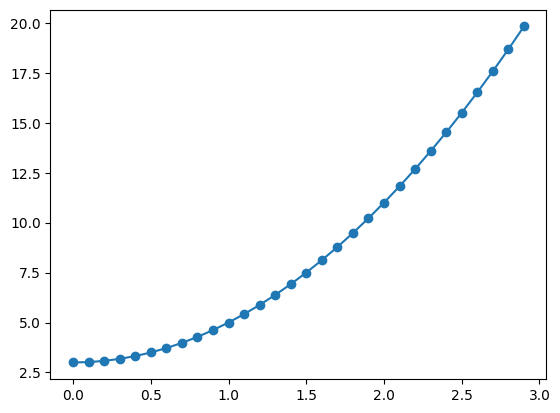

In [3]:
# 便利な関数たちを呼び出して使えます。
import numpy as np # 数値計算用（Numerical Pythonの略）
import matplotlib.pyplot as plt  # グラフプロット用

x = np.arange(0, 3, 0.1) #0から3まで0.1刻み。3は含まれないことに注意。
y = a*(x**2) + b
plt.plot( x, y , 'o-' )
print(x)  # printをつけると最後の行じゃなくても出力します。
print(y)  # printをつけると最後の行じゃなくても出力します。


### いきなりですが、データを統計解析してみます


In [4]:
# ① CSVを読み込む
import pandas as pd
from scipy import stats

url = 'https://raw.githubusercontent.com/hosodakazufumi/note/main/data/phq9_training_160.csv'
df = pd.read_csv(url)

df


,id,group,age,sex,pre_q1,pre_q2,pre_q3,pre_q4,pre_q5,pre_q6,...,week8_q3,week8_q4,week8_q5,week8_q6,week8_q7,week8_q8,week8_q9,pre_total,week8_total,improvement
0,P001,B,52,F,2,3,2,2,0,1,...,1,2,0,1,1,1,0,13,10,3
1,P002,C,48,M,2,1,1,1,0,2,...,1,0,0,0,2,0,0,9,4,5
2,P003,C,40,F,2,2,2,1,2,2,...,2,1,0,2,1,2,2,17,14,3
3,P004,B,68,F,2,2,1,3,1,2,...,1,2,1,1,2,2,0,15,12,3
4,P005,B,56,F,1,2,2,1,1,2,...,2,1,0,2,1,2,2,15,13,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
155,P156,A,49,F,2,2,2,1,0,2,...,2,1,0,2,2,1,0,12,13,-1
156,P157,D,60,F,0,2,1,2,1,1,...,0,0,0,0,0,0,0,9,0,9
157,P158,A,74,F,2,2,2,2,2,1,...,2,2,2,2,2,2,2,17,18,-1
158,P159,C,54,M,3,2,1,0,0,1,...,0,0,0,0,0,0,0,9,1,8


In [5]:
# 列を足す
df["pre_ge10"] = (df["pre_total"] >= 10).astype(int)
df["week8_ge10"] = (df["week8_total"] >= 10).astype(int)


In [6]:
# ② データを眺める
df.head() # 上だけ

,id,group,age,sex,pre_q1,pre_q2,pre_q3,pre_q4,pre_q5,pre_q6,...,week8_q5,week8_q6,week8_q7,week8_q8,week8_q9,pre_total,week8_total,improvement,pre_ge10,week8_ge10
0,P001,B,52,F,2,3,2,2,0,1,...,0,1,1,1,0,13,10,3,1,1
1,P002,C,48,M,2,1,1,1,0,2,...,0,0,2,0,0,9,4,5,0,0
2,P003,C,40,F,2,2,2,1,2,2,...,0,2,1,2,2,17,14,3,1,1
3,P004,B,68,F,2,2,1,3,1,2,...,1,1,2,2,0,15,12,3,1,1
4,P005,B,56,F,1,2,2,1,1,2,...,0,2,1,2,2,15,13,2,1,1


In [7]:
df.shape

(160, 27)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 27 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           160 non-null    object
 1   group        160 non-null    object
 2   age          160 non-null    int64 
 3   sex          160 non-null    object
 4   pre_q1       160 non-null    int64 
 5   pre_q2       160 non-null    int64 
 6   pre_q3       160 non-null    int64 
 7   pre_q4       160 non-null    int64 
 8   pre_q5       160 non-null    int64 
 9   pre_q6       160 non-null    int64 
 10  pre_q7       160 non-null    int64 
 11  pre_q8       160 non-null    int64 
 12  pre_q9       160 non-null    int64 
 13  week8_q1     160 non-null    int64 
 14  week8_q2     160 non-null    int64 
 15  week8_q3     160 non-null    int64 
 16  week8_q4     160 non-null    int64 
 17  week8_q5     160 non-null    int64 
 18  week8_q6     160 non-null    int64 
 19  week8_q7     160 non-null    

<Axes: xlabel='group', ylabel='improvement'>

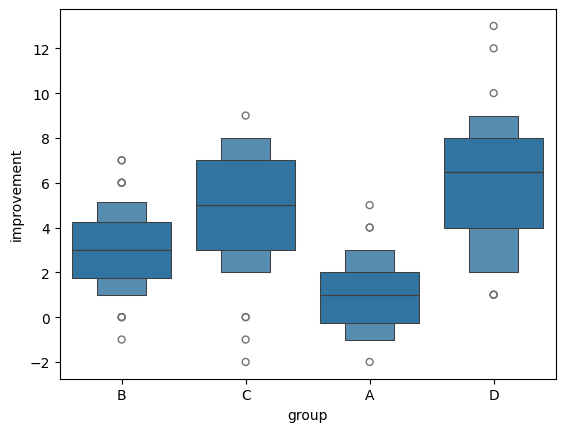

In [9]:
# とりあえずプロット
import seaborn as sns

sns.boxenplot(data=df, x="group", y="improvement")


In [10]:
# ③ 記述統計
df[["age", "pre_total", "week8_total", "improvement"]].describe()

,age,pre_total,week8_total,improvement
count,160.000000,160.00000,160.000000,160.00000
mean,51.287500,13.04375,9.293750,3.75000
std,16.200546,3.86135,4.792023,3.05505
min,18.000000,2.00000,0.000000,-2.00000
25%,41.000000,10.00000,6.000000,1.00000
50%,51.000000,13.00000,9.000000,4.00000
75%,62.000000,16.00000,13.000000,6.00000
max,82.000000,22.00000,22.000000,13.00000


In [11]:
# ④ 4群の平均・中央値を比較
df.groupby("group")["improvement"].agg( ["count", "mean", "median", "std"] )


,count,mean,median,std
group,,,,
A,40,0.975,1.0,1.701997
B,40,3.100,3.0,2.022945
C,40,4.775,5.0,2.674548
D,40,6.150,6.5,2.931264


In [12]:
# ⑤ 同じ人の介入前後を比較

# A群の改善量
a = df[df["group"] == "A"]
diff = a["pre_total"] - a["week8_total"]

# 対応のあるウィルコクソン検定
stats.wilcoxon( diff )


WilcoxonResult(statistic=np.float64(102.5), pvalue=np.float64(0.001192849119124408))

In [13]:
# 符号検定
stats.binomtest( (diff > 0).sum(), (diff != 0).sum(), p=0.5)


BinomTestResult(k=23, n=33, alternative='two-sided', statistic=0.696969696969697, pvalue=0.03508203336969018)

In [14]:
# ⑥ 4群の差を検定

groups = ["A", "B", "C", "D"]

samples = [ df[df["group"] == g]["improvement"]  for g in groups ]

stats.kruskal(*samples)


KruskalResult(statistic=np.float64(65.46916148076527), pvalue=np.float64(3.98105828870188e-14))

In [15]:
# ⑦ 多重比較：Manwihtneyu + Holm法

from itertools import combinations
from statsmodels.stats.multitest import multipletests

pairs = list(combinations(groups, 2))

p_values = []
for g1, g2 in pairs:
    x = df[df["group"] == g1]["improvement"]
    y = df[df["group"] == g2]["improvement"]

    p = stats.mannwhitneyu(x, y).pvalue
    p_values.append(p)

# Holm法による多重比較補正
adjusted = multipletests(p_values, method="holm")[1]

pd.DataFrame({
    "比較": [f"{a}-{b}" for a, b in pairs],
    "補正前p": p_values,
    "Holm補正後p": adjusted,
    "Bonferroni補正後p": np.array(p_values)*len(p_values) # (実際にはαを割るのですが、今回は同じことなのでpにかけた)
})



,比較,補正前p,Holm補正後p,Bonferroni補正後p
0,A-B,1.184930e-05,3.554790e-05,7.109581e-05
1,A-C,5.102594e-09,2.551297e-08,3.061557e-08
2,A-D,2.819450e-11,1.691670e-10,1.691670e-10
3,B-C,1.761052e-03,3.522104e-03,1.056631e-02
4,B-D,3.925924e-06,1.570370e-05,2.355554e-05
5,C-D,4.771804e-02,4.771804e-02,2.863082e-01


In [16]:
# 初回のみ
!pip install scikit-posthocs

In [17]:
# Dunn + Holm法

import scikit_posthocs as sp

data = df[
    df["group"].isin(["A", "B", "C", "D"])
][["group", "improvement"]].dropna()

result = sp.posthoc_dunn(
    data,
    val_col="improvement",
    group_col="group",
    p_adjust="holm"
)

print(result)

              A         B             C             D
A  1.000000e+00  0.002141  1.102761e-08  2.508287e-13
B  2.140896e-03  1.000000  1.877498e-02  1.213250e-04
C  1.102761e-08  0.018775  1.000000e+00  1.156368e-01
D  2.508287e-13  0.000121  1.156368e-01  1.000000e+00


In [18]:
# Steel-Dwass系の多重比較（DSCF）
import scikit_posthocs as sp

data = df[df["group"].isin(["A", "B", "C", "D"])]
data = data[["group", "improvement"]].dropna()

result = sp.posthoc_dscf(
    data,
    val_col="improvement",
    group_col="group"
)

print(result)

          B             C             A             D
B  1.000000  9.385422e-03  6.838960e-05  2.275773e-05
C  0.009385  1.000000e+00  2.970630e-08  1.936977e-01
A  0.000068  2.970630e-08  1.000000e+00  1.636662e-10
D  0.000023  1.936977e-01  1.636662e-10  1.000000e+00


In [19]:
# カイ二乗検定・フィッシャー検定

# 4群の割合の違い
table = pd.crosstab(df["group"], df["week8_ge10"])

print(stats.chi2_contingency(table))

# A群とD群だけの割合を比較
ad = df[df["group"].isin(["A", "D"])]
table_ad = pd.crosstab(ad["group"], ad["week8_ge10"])

print(stats.fisher_exact(table_ad))


Chi2ContingencyResult(statistic=np.float64(13.032581453634085), pvalue=np.float64(0.004566673339651556), dof=3, expected_freq=array([[21., 19.],
       [21., 19.],
       [21., 19.],
       [21., 19.]]))
SignificanceResult(statistic=np.float64(0.23076923076923078), pvalue=np.float64(0.0033454178373728497))


In [20]:
# マクネマー検定

from statsmodels.stats.contingency_tables import mcnemar

# D群の同じ患者の前後変化
d = df[df["group"] == "D"]

table = pd.crosstab(
    d["pre_ge10"],
    d["week8_ge10"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

print(table)
print(mcnemar(table, exact=True))


week8_ge10   0   1
pre_ge10          
0            8   0
1           20  12
pvalue      1.9073486328125e-06
statistic   0.0


In [21]:
# スピアマンの順位相関

rho, p = stats.spearmanr(
    df["pre_total"],
    df["week8_total"]
)

print("順位相関係数:", rho)
print("p値:", p)


順位相関係数: 0.7598135072041399
p値: 2.3683992324050524e-31


In [22]:
# 線形回帰・ロジスティック回帰

import statsmodels.formula.api as smf

# 線形回帰：8週間後のPHQ-9合計点を説明
model1 = smf.ols(
    "week8_total ~ pre_total + age + C(group)",
    data=df
).fit()

print(model1.summary())

# ロジスティック回帰：8週間後に10点以上かを説明
model2 = smf.logit(
    "week8_ge10 ~ pre_total + age + C(group)",
    data=df
).fit(disp=False)

print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:            week8_total   R-squared:                       0.760
Model:                            OLS   Adj. R-squared:                  0.752
Method:                 Least Squares   F-statistic:                     97.50
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           6.70e-46
Time:                        09:14:27   Log-Likelihood:                -363.09
No. Observations:                 160   AIC:                             738.2
Df Residuals:                     154   BIC:                             756.6
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.0443      0.960      0.046